#### Подключение PySpark, загрузка библиотек, настройка изображений

In [43]:
import numpy as np
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession
from pyspark.sql.functions import col, mean, countDistinct, count, size, when, regexp_extract, split, lit, try_element_at

sns.set_style('darkgrid')
params = {'legend.fontsize': 'medium', 'figure.figsize': (10,8), 'figure.dpi': 100, 'axes.labelsize': 'medium', 'axes.titlesize': 'medium', 'xtick.labelsize': 'medium', 'ytick.labelsize': 'medium' }
plt.rcParams.update(params)

#### Запуск сессии Spark

In [ ]:
spark = SparkSession.builder.appName('EDA Films').getOrCreate()

#### Загрузка и обзор датасетов

In [45]:
df_movies = spark.read.csv('sp_movies.csv', header=True, inferSchema=True)
df_ratings = spark.read.csv('sp_ratings.csv', header=True, inferSchema=True)
df_tags = spark.read.csv('sp_tags.csv', header=True, inferSchema=True)

In [46]:
df_movies.show(20, truncate=False)

+-------+-------------------------------------+-------------------------------------------+
|movieId|title                                |genres                                     |
+-------+-------------------------------------+-------------------------------------------+
|1      |Toy Story (1995)                     |Adventure|Animation|Children|Comedy|Fantasy|
|2      |Jumanji (1995)                       |Adventure|Children|Fantasy                 |
|3      |Grumpier Old Men (1995)              |Comedy|Romance                             |
|4      |Waiting to Exhale (1995)             |Comedy|Drama|Romance                       |
|5      |Father of the Bride Part II (1995)   |Comedy                                     |
|6      |Heat (1995)                          |Action|Crime|Thriller                      |
|7      |Sabrina (1995)                       |Comedy|Romance                             |
|8      |Tom and Huck (1995)                  |Adventure|Children               

In [47]:
df_ratings.show(20, truncate=False)

+------+-------+------+---------+
|userId|movieId|rating|timestamp|
+------+-------+------+---------+
|1     |1      |4.0   |964982703|
|1     |3      |4.0   |964981247|
|1     |6      |4.0   |964982224|
|1     |47     |5.0   |964983815|
|1     |50     |5.0   |964982931|
|1     |70     |3.0   |964982400|
|1     |101    |5.0   |964980868|
|1     |110    |4.0   |964982176|
|1     |151    |5.0   |964984041|
|1     |157    |5.0   |964984100|
|1     |163    |5.0   |964983650|
|1     |216    |5.0   |964981208|
|1     |223    |3.0   |964980985|
|1     |231    |5.0   |964981179|
|1     |235    |4.0   |964980908|
|1     |260    |5.0   |964981680|
|1     |296    |3.0   |964982967|
|1     |316    |3.0   |964982310|
|1     |333    |5.0   |964981179|
|1     |349    |4.0   |964982563|
+------+-------+------+---------+
only showing top 20 rows


In [48]:
df_tags.show(20, truncate=False)

+------+-------+-----------------+----------+
|userId|movieId|tag              |timestamp |
+------+-------+-----------------+----------+
|2     |60756  |funny            |1445714994|
|2     |60756  |Highly quotable  |1445714996|
|2     |60756  |will ferrell     |1445714992|
|2     |89774  |Boxing story     |1445715207|
|2     |89774  |MMA              |1445715200|
|2     |89774  |Tom Hardy        |1445715205|
|2     |106782 |drugs            |1445715054|
|2     |106782 |Leonardo DiCaprio|1445715051|
|2     |106782 |Martin Scorsese  |1445715056|
|7     |48516  |way too long     |1169687325|
|18    |431    |Al Pacino        |1462138765|
|18    |431    |gangster         |1462138749|
|18    |431    |mafia            |1462138755|
|18    |1221   |Al Pacino        |1461699306|
|18    |1221   |Mafia            |1461699303|
|18    |5995   |holocaust        |1455735472|
|18    |5995   |true story       |1455735479|
|18    |44665  |twist ending     |1456948283|
|18    |52604  |Anthony Hopkins  |

#### Статистика

In [49]:
print('Количество пользователей поставивших оценку:')
df_ratings.select(countDistinct('userId')).show()

Количество пользователей поставивших оценку:
+----------------------+
|count(DISTINCT userId)|
+----------------------+
|                   610|
+----------------------+



In [50]:
print('Количество оцененных фильмов:')
df_ratings.select(countDistinct('movieId')).show()

Количество оцененных фильмов:
+-----------------------+
|count(DISTINCT movieId)|
+-----------------------+
|                   9724|
+-----------------------+



In [51]:
print('Количество фильмов с коментариями (tags):')
df_tags.select(countDistinct('movieId')).show()

Количество фильмов с коментариями (tags):
+-----------------------+
|count(DISTINCT movieId)|
+-----------------------+
|                   1572|
+-----------------------+



In [52]:
print('Количество коментариев (уникальных) к фильмам:')
df_tags.select(countDistinct('tag')).show()

Количество коментариев (уникальных) к фильмам:
+-------------------+
|count(DISTINCT tag)|
+-------------------+
|               1589|
+-------------------+



#### Предобработка и настройка данных

In [53]:
df1 = df_ratings.alias('df1')
df2 = df_tags.alias('df2')
df3 = df_movies.alias('df3')

In [54]:
df3.show()

+-------+--------------------+--------------------+
|movieId|               title|              genres|
+-------+--------------------+--------------------+
|      1|    Toy Story (1995)|Adventure|Animati...|
|      2|      Jumanji (1995)|Adventure|Childre...|
|      3|Grumpier Old Men ...|      Comedy|Romance|
|      4|Waiting to Exhale...|Comedy|Drama|Romance|
|      5|Father of the Bri...|              Comedy|
|      6|         Heat (1995)|Action|Crime|Thri...|
|      7|      Sabrina (1995)|      Comedy|Romance|
|      8| Tom and Huck (1995)|  Adventure|Children|
|      9| Sudden Death (1995)|              Action|
|     10|    GoldenEye (1995)|Action|Adventure|...|
|     11|American Presiden...|Comedy|Drama|Romance|
|     12|Dracula: Dead and...|       Comedy|Horror|
|     13|        Balto (1995)|Adventure|Animati...|
|     14|        Nixon (1995)|               Drama|
|     15|Cutthroat Island ...|Action|Adventure|...|
|     16|       Casino (1995)|         Crime|Drama|
|     17|Sen

#### Извлечение года из названия

In [55]:
df3 = df3.withColumn('year', regexp_extract(df3['title'], r'\((\d{4})\)', 1))


In [56]:
df3.show(10, truncate=False)

+-------+----------------------------------+-------------------------------------------+----+
|movieId|title                             |genres                                     |year|
+-------+----------------------------------+-------------------------------------------+----+
|1      |Toy Story (1995)                  |Adventure|Animation|Children|Comedy|Fantasy|1995|
|2      |Jumanji (1995)                    |Adventure|Children|Fantasy                 |1995|
|3      |Grumpier Old Men (1995)           |Comedy|Romance                             |1995|
|4      |Waiting to Exhale (1995)          |Comedy|Drama|Romance                       |1995|
|5      |Father of the Bride Part II (1995)|Comedy                                     |1995|
|6      |Heat (1995)                       |Action|Crime|Thriller                      |1995|
|7      |Sabrina (1995)                    |Comedy|Romance                             |1995|
|8      |Tom and Huck (1995)               |Adventure|Childr

#### Извлечение данных о жанрах

In [57]:
from functools import reduce

split_expr = split(df3['genres'], r'\|')

for i in range(1, 11):
    df3 = df3.withColumn(
        f'genre{i}',
        try_element_at(split_expr, lit(i))
    )

genre_columns = [f'genre{i}' for i in range(1, 11)]

genre_coint_expr = reduce(
    lambda a, b: a + b,
    [
        when(
            col(col_name).isNotNull() & (col(col_name) != '0'),
            1
        ).otherwise(0)
        for col_name in genre_columns
    ]
)

df3 = df3.withColumn(
    'genre_count',
    size(split_expr)
)


In [58]:
df3.show(truncate=False)

+-------+-------------------------------------+-------------------------------------------+----+---------+---------+--------+------+--------+------+------+------+------+-------+-----------+
|movieId|title                                |genres                                     |year|genre1   |genre2   |genre3  |genre4|genre5  |genre6|genre7|genre8|genre9|genre10|genre_count|
+-------+-------------------------------------+-------------------------------------------+----+---------+---------+--------+------+--------+------+------+------+------+-------+-----------+
|1      |Toy Story (1995)                     |Adventure|Animation|Children|Comedy|Fantasy|1995|Adventure|Animation|Children|Comedy|Fantasy |NULL  |NULL  |NULL  |NULL  |NULL   |5          |
|2      |Jumanji (1995)                       |Adventure|Children|Fantasy                 |1995|Adventure|Children |Fantasy |NULL  |NULL    |NULL  |NULL  |NULL  |NULL  |NULL   |3          |
|3      |Grumpier Old Men (1995)              |Com

#### Анализ данных

In [59]:
rating_avg = df1.groupBy('movieId').agg(mean('rating').alias('rating_avg'))
rating_avg = rating_avg.withColumnRenamed('movieId', 'movieId_avg')
rating_avg.show()

+-----------+------------------+
|movieId_avg|        rating_avg|
+-----------+------------------+
|       1580| 3.487878787878788|
|       2366|              3.64|
|       3175|              3.58|
|       1088| 3.369047619047619|
|      32460|              4.25|
|      44022| 3.217391304347826|
|      96488|              4.25|
|       1238| 4.055555555555555|
|       1342|               2.5|
|       1591|2.6346153846153846|
|       1645| 3.411764705882353|
|       4519|3.3333333333333335|
|       2142|               2.7|
|        471|              3.55|
|       3997|1.8333333333333333|
|        833|               2.0|
|       3918|3.2777777777777777|
|       7982|              3.25|
|       1959|3.6666666666666665|
|      68135|              3.55|
+-----------+------------------+
only showing top 20 rows


In [60]:
rating_count = df1.groupBy('movieId').agg(count('rating').alias('rating_count'))
rating_count = rating_count.withColumnRenamed('movieId', 'movieId_count')
rating_count.show()

+-------------+------------+
|movieId_count|rating_count|
+-------------+------------+
|         1580|         165|
|         2366|          25|
|         3175|          75|
|         1088|          42|
|        32460|           4|
|        44022|          23|
|        96488|           4|
|         1238|           9|
|         1342|          11|
|         1591|          26|
|         1645|          51|
|         4519|           9|
|         2142|          10|
|          471|          40|
|         3997|          12|
|          833|           6|
|         3918|           9|
|         7982|           4|
|         1959|          15|
|        68135|          10|
+-------------+------------+
only showing top 20 rows


In [61]:
user_rating = df1.groupBy('userId').agg(mean('rating').alias('user_rating_avg'))
user_rating = user_rating.withColumnRenamed('userId', 'userId_avg')
user_rating.show()

+----------+------------------+
|userId_avg|   user_rating_avg|
+----------+------------------+
|       148|3.7395833333333335|
|       463| 3.787878787878788|
|       471|             3.875|
|       496| 3.413793103448276|
|       243| 4.138888888888889|
|       392|               3.2|
|       540|               4.0|
|        31|              3.92|
|       516|3.6923076923076925|
|        85|3.7058823529411766|
|       137| 3.978723404255319|
|       251| 4.869565217391305|
|       451|3.7941176470588234|
|       580| 3.529816513761468|
|        65| 4.029411764705882|
|       458|4.1525423728813555|
|        53|               5.0|
|       255|2.5681818181818183|
|       481| 2.806451612903226|
|       588|              3.25|
+----------+------------------+
only showing top 20 rows


In [62]:
user_count = df1.groupBy('userId').agg(count('rating').alias('user_rating_count'))
user_count = user_count.withColumnRenamed('userId', 'userId_count')
user_count.show()

+------------+-----------------+
|userId_count|user_rating_count|
+------------+-----------------+
|         148|               48|
|         463|               33|
|         471|               28|
|         496|               29|
|         243|               36|
|         392|               25|
|         540|               42|
|          31|               50|
|         516|               26|
|          85|               34|
|         137|              141|
|         251|               23|
|         451|               34|
|         580|              436|
|          65|               34|
|         458|               59|
|          53|               20|
|         255|               44|
|         481|               31|
|         588|               56|
+------------+-----------------+
only showing top 20 rows


In [63]:
df_movie = rating_avg.join(rating_count, col('movieId_avg') == col('movieId_count'), 'inner').drop('movieId_count')
df_movie.show(20)

+-----------+------------------+------------+
|movieId_avg|        rating_avg|rating_count|
+-----------+------------------+------------+
|       1580| 3.487878787878788|         165|
|       2366|              3.64|          25|
|       3175|              3.58|          75|
|       1088| 3.369047619047619|          42|
|      32460|              4.25|           4|
|      44022| 3.217391304347826|          23|
|      96488|              4.25|           4|
|       1238| 4.055555555555555|           9|
|       1342|               2.5|          11|
|       1591|2.6346153846153846|          26|
|       1645| 3.411764705882353|          51|
|       4519|3.3333333333333335|           9|
|       2142|               2.7|          10|
|        471|              3.55|          40|
|       3997|1.8333333333333333|          12|
|        833|               2.0|           6|
|       3918|3.2777777777777777|           9|
|       7982|              3.25|           4|
|       1959|3.6666666666666665|  

In [64]:
df_user = user_rating.join(user_count, col('userId_avg') == col('userId_count'), 'inner').drop('userId_count')
df_user.show(20)

+----------+------------------+-----------------+
|userId_avg|   user_rating_avg|user_rating_count|
+----------+------------------+-----------------+
|       148|3.7395833333333335|               48|
|       463| 3.787878787878788|               33|
|       471|             3.875|               28|
|       496| 3.413793103448276|               29|
|       243| 4.138888888888889|               36|
|       392|               3.2|               25|
|       540|               4.0|               42|
|        31|              3.92|               50|
|       516|3.6923076923076925|               26|
|        85|3.7058823529411766|               34|
|       137| 3.978723404255319|              141|
|       251| 4.869565217391305|               23|
|       451|3.7941176470588234|               34|
|       580| 3.529816513761468|              436|
|        65| 4.029411764705882|               34|
|       458|4.1525423728813555|               59|
|        53|               5.0|               20|


In [65]:
df_user.sort(col('user_rating_count').desc()).show()

+----------+------------------+-----------------+
|userId_avg|   user_rating_avg|user_rating_count|
+----------+------------------+-----------------+
|       414| 3.391957005189029|             2698|
|       599|2.6420500403551253|             2478|
|       474| 3.398956356736243|             2108|
|       448|2.8473712446351933|             1864|
|       274| 3.235884101040119|             1346|
|       610|3.6885560675883258|             1302|
|        68| 3.233730158730159|             1260|
|       380|3.6732348111658455|             1218|
|       606|3.6573991031390136|             1115|
|       288|3.1459715639810426|             1055|
|       249|3.6964627151051626|             1046|
|       387|3.2585199610516065|             1027|
|       182|3.5112589559877176|              977|
|       307|2.6656410256410257|              975|
|       603|3.5079533404029695|              943|
|       298| 2.363684771033014|              939|
|       177| 3.375553097345133|              904|


In [66]:
df_movie.sort(col('rating_avg').desc()).show()

+-----------+----------+------------+
|movieId_avg|rating_avg|rating_count|
+-----------+----------+------------+
|      26350|       5.0|           1|
|       3795|       5.0|           1|
|      25887|       5.0|           1|
|     157775|       5.0|           1|
|        633|       5.0|           1|
|      33138|       5.0|           1|
|      67618|       5.0|           1|
|        876|       5.0|           1|
|        496|       5.0|           1|
|      27373|       5.0|           1|
|     113829|       5.0|           1|
|      53578|       5.0|           1|
|     152711|       5.0|           1|
|     118894|       5.0|           1|
|         53|       5.0|           2|
|     160644|       5.0|           1|
|        148|       5.0|           1|
|      84273|       5.0|           1|
|     159811|       5.0|           1|
|     150554|       5.0|           1|
+-----------+----------+------------+
only showing top 20 rows


In [67]:
df2.show(5)

+------+-------+---------------+----------+
|userId|movieId|            tag| timestamp|
+------+-------+---------------+----------+
|     2|  60756|          funny|1445714994|
|     2|  60756|Highly quotable|1445714996|
|     2|  60756|   will ferrell|1445714992|
|     2|  89774|   Boxing story|1445715207|
|     2|  89774|            MMA|1445715200|
+------+-------+---------------+----------+
only showing top 5 rows


In [68]:
user_tags = df2.groupBy('userId', 'movieId').agg(count('tag').alias('tag_count'))
user_tags.show()

+------+-------+---------+
|userId|movieId|tag_count|
+------+-------+---------+
|    62| 108190|        8|
|   474|    412|        1|
|   474|    551|        2|
|   474|   1348|        1|
|   474|   1513|        1|
|   474|   4027|        1|
|   474|   5876|        1|
|   474|   6380|        1|
|   474|   8014|        1|
|   474|  30707|        1|
|   125|  60950|        1|
|   424|   3499|        7|
|   474|     32|        1|
|   474|     43|        1|
|   474|   1797|        1|
|   474|   4117|        1|
|   474|   5644|        2|
|   477|  62336|        4|
|   119| 115149|        3|
|   318|  64034|        2|
+------+-------+---------+
only showing top 20 rows


In [69]:
user_tags.sort(col('tag_count').desc()).show()

+------+-------+---------+
|userId|movieId|tag_count|
+------+-------+---------+
|   599|    296|      173|
|   599|   2959|       48|
|   599|    924|       39|
|   599|    293|       32|
|   599|   1732|       31|
|   567|   7361|       24|
|    62| 135536|       19|
|   567|   4144|       18|
|   567|   3676|       16|
|   567|  71899|       13|
|   567|   4878|       13|
|   537|  79132|       13|
|   567|   1921|       12|
|   567|   5673|       12|
|   477|  68791|       12|
|    62|  99114|       11|
|   125|   7022|       10|
|    62| 122912|       10|
|   477|  72998|       10|
|   477|  61323|       10|
+------+-------+---------+
only showing top 20 rows


In [70]:
movie_tagcount = df2.groupBy('movieId').agg(count('tag').alias('tag_count'))
cols = ['movieId', 'genre_count', 'genre1']
dfs = df3.select(*cols)

movie_tagcount = movie_tagcount.join(dfs, on='movieId', how='inner')
movie_tagcount.show()


+-------+---------+-----------+---------+
|movieId|tag_count|genre_count|   genre1|
+-------+---------+-----------+---------+
|      1|        3|          5|Adventure|
|      2|        4|          3|Adventure|
|      3|        2|          2|   Comedy|
|      5|        2|          1|   Comedy|
|      7|        1|          2|   Comedy|
|     11|        2|          3|   Comedy|
|     14|        2|          1|    Drama|
|     16|        1|          2|    Crime|
|     17|        1|          2|    Drama|
|     21|        1|          3|   Comedy|
|     22|        1|          5|    Crime|
|     25|        1|          2|    Drama|
|     26|        1|          1|    Drama|
|     28|        2|          2|    Drama|
|     29|        1|          5|Adventure|
|     31|        2|          1|    Drama|
|     32|       10|          3|  Mystery|
|     34|        3|          2| Children|
|     36|        2|          2|    Crime|
|     38|        1|          2| Children|
+-------+---------+-----------+---

In [71]:
movie_tagcount.sort(col('tag_count').desc()).show()

+-------+---------+-----------+---------+
|movieId|tag_count|genre_count|   genre1|
+-------+---------+-----------+---------+
|    296|      181|          4|   Comedy|
|   2959|       54|          4|   Action|
|    924|       41|          3|Adventure|
|    293|       35|          4|   Action|
|   7361|       34|          3|    Drama|
|   1732|       32|          2|   Comedy|
|   4878|       29|          4|    Drama|
|    260|       26|          3|   Action|
|  79132|       26|          7|   Action|
| 135536|       19|          3|   Action|
|  72998|       18|          4|   Action|
|   4144|       18|          2|    Drama|
|   1921|       17|          3|    Drama|
|   3676|       17|          2|    Drama|
| 122912|       15|          3|   Action|
|    541|       13|          3|   Action|
|  71899|       13|          3|Animation|
|   4226|       13|          2|  Mystery|
|   5673|       13|          3|   Comedy|
|  68954|       13|          4|Adventure|
+-------+---------+-----------+---

In [72]:
df_movie_renamed = df_movie.withColumnRenamed('movieId_avg', 'movieId')
df3 = df3.join(df_movie_renamed, on = 'movieId', how = 'inner')

df3 = df3.withColumnRenamed('rating_avg', 'rating')
df3.show()

+-------+--------------------+--------------------+----+-----------+---------+--------+--------+-------+------+------+------+------+-------+-----------+------------------+------------+
|movieId|               title|              genres|year|     genre1|   genre2|  genre3|  genre4| genre5|genre6|genre7|genre8|genre9|genre10|genre_count|            rating|rating_count|
+-------+--------------------+--------------------+----+-----------+---------+--------+--------+-------+------+------+------+------+-------+-----------+------------------+------------+
|   1580|Men in Black (a.k...|Action|Comedy|Sci-Fi|1997|     Action|   Comedy|  Sci-Fi|    NULL|   NULL|  NULL|  NULL|  NULL|  NULL|   NULL|          3| 3.487878787878788|         165|
|   2366|    King Kong (1933)|Action|Adventure|...|1933|     Action|Adventure| Fantasy|  Horror|   NULL|  NULL|  NULL|  NULL|  NULL|   NULL|          4|              3.64|          25|
|   3175| Galaxy Quest (1999)|Adventure|Comedy|...|1999|  Adventure|   Come

#### Лучшие фильмы по жанрам

In [73]:
df3.groupBy('genre1') \
    .agg({'rating': 'avg', 'rating_count': 'sum'}) \
    .withColumnRenamed('avg(rating)', 'avg_rating') \
    .withColumnRenamed('sum(rating_count)', 'total_votes') \
    .orderBy(col('avg_rating').desc()) \
    .show()

+------------------+------------------+-----------+
|            genre1|        avg_rating|total_votes|
+------------------+------------------+-----------+
|         Film-Noir|3.8562184343434347|        112|
|       Documentary|3.7889134809499603|       1015|
|         Animation| 3.574865409400964|       2549|
|               War|             3.525|          9|
|           Western|3.4715869878913357|        151|
|             Drama|3.4609149865486173|      17068|
|             Crime|3.4122601226160905|       6610|
|(no genres listed)|3.3711484593837535|         47|
|         Adventure|3.2851788575659153|      10344|
|           Musical| 3.276388888888889|        134|
|           Romance|3.2052944862155393|        125|
|            Comedy| 3.193690704718599|      25217|
|           Fantasy|3.1797741128192873|        315|
|           Mystery|3.1481526997179983|        976|
|            Action|3.0944984491955116|      30635|
|            Sci-Fi|3.0669590956205637|        343|
|          T

#### Фильмы с самым высоким рейтингом (при условии min голосов)

In [78]:
df3.filter(col('rating_count') > 100) \
    .orderBy(col('rating').desc()) \
    .select('title', 'year', 'rating', 'rating_count') \
    .show(10, truncate=False)

+-----------------------------------------+----+-----------------+------------+
|title                                    |year|rating           |rating_count|
+-----------------------------------------+----+-----------------+------------+
|Shawshank Redemption, The (1994)         |1994|4.429022082018927|317         |
|Godfather, The (1972)                    |1972|4.2890625        |192         |
|Fight Club (1999)                        |1999|4.272935779816514|218         |
|Godfather: Part II, The (1974)           |1974|4.25968992248062 |129         |
|Departed, The (2006)                     |2006|4.252336448598131|107         |
|Goodfellas (1990)                        |1990|4.25             |126         |
|Dark Knight, The (2008)                  |2008|4.238255033557047|149         |
|Usual Suspects, The (1995)               |1995|4.237745098039215|204         |
|Princess Bride, The (1987)               |1987|4.232394366197183|142         |
|Star Wars: Episode IV - A New Hope (197

#### Распределение рейтингов по годам

In [79]:
df3.groupBy('year') \
    .avg('rating') \
    .withColumnRenamed('avg(rating)', 'avg_rating') \
    .orderBy(col('year').desc()) \
    .show()

+----+------------------+
|year|        avg_rating|
+----+------------------+
|2018| 3.372560975609756|
|2017| 3.376748925992123|
|2016|3.1037478772713865|
|2015| 3.069094481486622|
|2014| 3.113463769437626|
|2013|3.2600931407100666|
|2012|3.1783623736766464|
|2011| 3.303575316235587|
|2010| 3.346163855868465|
|2009| 3.334303702119075|
|2008|3.2835361408519486|
|2007| 3.324551305753915|
|2006|3.2665519559156486|
|2005| 3.194025772552653|
|2004| 3.313308348476884|
|2003| 3.220392423415188|
|2002| 3.203956659932012|
|2001|3.2459847936008766|
|2000|3.2233973500852326|
|1999|3.2621801101857706|
+----+------------------+
only showing top 20 rows


In [80]:
df3.groupBy('year') \
    .avg('rating') \
    .withColumnRenamed('avg(rating)', 'avg_rating') \
    .orderBy(col('avg_rating').desc()) \
    .show()

+----+------------------+
|year|        avg_rating|
+----+------------------+
|1917|               4.5|
|1921|               4.1|
|1934|4.0511904761904765|
|1908|               4.0|
|1926|               4.0|
|1930|             3.995|
|1944|3.9772608181203517|
|1935| 3.850871350871351|
|1971|3.8112428924850703|
|1957|3.7676802486013017|
|1941| 3.762480394002133|
|1942|3.7215948963317387|
|1937|3.7186147186147185|
|1951| 3.718043884220355|
|1948|3.7156798245614033|
|1928|3.7145833333333336|
|    |3.7115384615384617|
|1952|3.7001038167226574|
|1924|               3.7|
|1938| 3.687962962962963|
+----+------------------+
only showing top 20 rows


#### Диаграмма рассеяния "Рейтинг / Кол-во голосов"

/opt/anaconda3/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


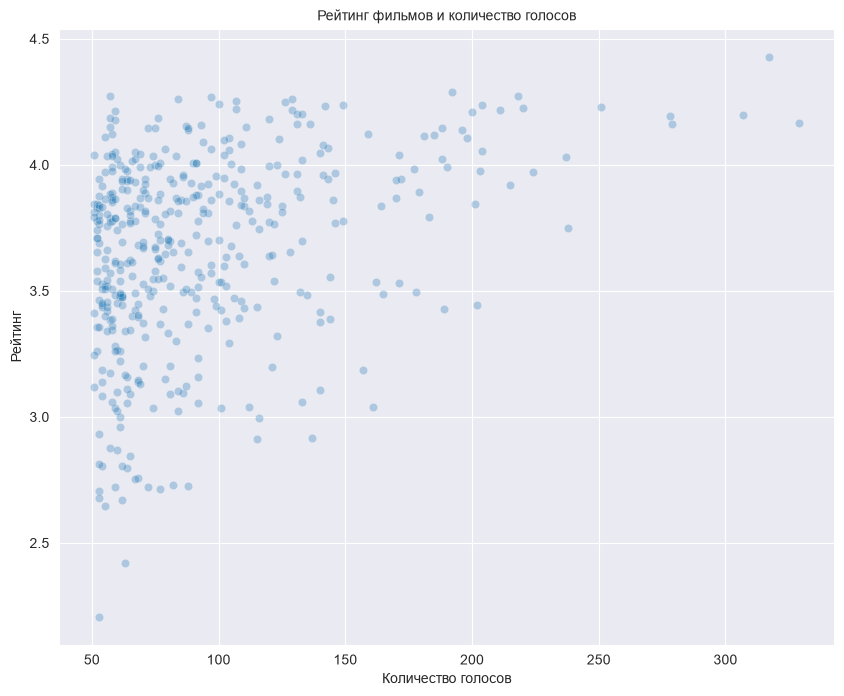

In [87]:
top = df3.filter(df3.rating_count > 50).select('rating', 'rating_count').toPandas()
sns.scatterplot(data=top, x='rating_count', y='rating', alpha=0.3)
plt.title('Рейтинг фильмов и количество голосов')
plt.xlabel('Количество голосов')
plt.ylabel('Рейтинг')
#plt.xscale('log')
plt.show()


In [88]:
spark.stop()